# Sizing Private Markets in a 60/40 Portfolio
**Selina Hach, October 2026**

A client holds 60% US stocks and 40% US bonds. What happens if they move 10%, 20% or 30% into
private credit, private equity, real estate and infrastructure?

1. What does each strategy add on its own?
2. What is the best way to split the money?
3. How much of the benefit is left if the money is locked up for 3 years?

Inputs come from J.P. Morgan's 2026 Long-Term Capital Market Assumptions (10-15 year outlook, USD).

## 1. Inputs
Expected return and volatility for each asset, and how they move together (correlation).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

names = ["Cash", "US bonds", "US stocks", "Private credit", "Private equity", "Real estate", "Infrastructure"]
inputs = pd.DataFrame({
    "return":     [0.0310, 0.0491, 0.0794, 0.0859, 0.1191, 0.0879, 0.0699],
    "volatility": [0.0067, 0.0476, 0.1647, 0.1401, 0.1978, 0.1139, 0.1025],
}, index=names)

corr = pd.DataFrame([
    [ 1.00,  0.10, 0.01, -0.06, -0.01, -0.12, 0.04],
    [ 0.10,  1.00, 0.30,  0.07,  0.01, -0.15, 0.06],
    [ 0.01,  0.30, 1.00,  0.55,  0.75,  0.35, 0.47],
    [-0.06,  0.07, 0.55,  1.00,  0.66,  0.35, 0.42],
    [-0.01,  0.01, 0.75,  0.66,  1.00,  0.32, 0.62],
    [-0.12, -0.15, 0.35,  0.35,  0.32,  1.00, 0.29],
    [ 0.04,  0.06, 0.47,  0.42,  0.62,  0.29, 1.00],
], index=names, columns=names)

inputs.style.format("{:.2%}")

,return,volatility
Cash,3.10%,0.67%
US bonds,4.91%,4.76%
US stocks,7.94%,16.47%
Private credit,8.59%,14.01%
Private equity,11.91%,19.78%
Real estate,8.79%,11.39%
Infrastructure,6.99%,10.25%


## 2. Covariance
Covariance combines volatility and correlation: `vol_i x vol_j x correlation_ij`.

In [2]:
mu  = inputs["return"].values
vol = inputs["volatility"].values
cov = np.outer(vol, vol) * corr.values
cash_rate = mu[0]

## 3. Three formulas everything is built on
- **Return** = sum of weight x expected return
- **Volatility** = square root of (weights x covariance x weights)
- **Sharpe ratio** = (return - cash) / volatility

In [3]:
def port_return(w, mu=mu):   return w @ mu
def port_vol(w, cov=cov):    return np.sqrt(w @ cov @ w)
def sharpe(w, mu=mu, cov=cov): return (port_return(w, mu) - cash_rate) / port_vol(w, cov)

def weights(**kw):
    """Build a weight vector from names, e.g. weights(stocks=0.6, bonds=0.4)."""
    keys = {"cash": 0, "bonds": 1, "stocks": 2, "credit": 3, "pe": 4, "re": 5, "infra": 6}
    w = np.zeros(7)
    for k, v in kw.items():
        w[keys[k]] = v
    return w

base = weights(stocks=0.60, bonds=0.40)
print(f"60/40:  return {port_return(base):.2%}   volatility {port_vol(base):.2%}   Sharpe {sharpe(base):.2f}")

60/40:  return 6.73%   volatility 10.61%   Sharpe 0.34


## 4. Add one strategy at a time
Take X% out of the 60/40 (from stocks and bonds in proportion) and put it into one strategy.

**Diversification** = how much less volatile the result is than if the strategy moved in lockstep with the 60/40.

In [4]:
private = ["Private credit", "Private equity", "Real estate", "Infrastructure"]
levels = [0.10, 0.20, 0.30]

rows = []
for s in private:
    i = names.index(s)
    for X in levels:
        w = (1 - X) * base
        w[i] += X
        lockstep_vol = (1 - X) * port_vol(base) + X * vol[i]
        rows.append({"strategy": s, "level": X,
                     "return change (bps)": (port_return(w) - port_return(base)) * 1e4,
                     "vol change (bps)":    (port_vol(w) - port_vol(base)) * 1e4,
                     "diversification (bps)": (lockstep_vol - port_vol(w)) * 1e4})
one_at_a_time = pd.DataFrame(rows)

print("At a 20% allocation:")
one_at_a_time[one_at_a_time.level == 0.20].set_index("strategy").drop(columns="level").round(0)

At a 20% allocation:


,return change (bps),vol change (bps),diversification (bps)
strategy,,,
Private credit,37.0,-37.0,105.0
Private equity,104.0,100.0,84.0
Real estate,41.0,-119.0,134.0
Infrastructure,5.0,-103.0,95.0


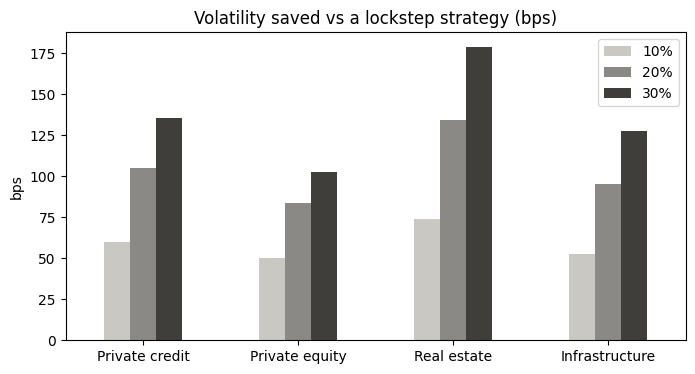

In [5]:
chart = one_at_a_time.pivot(index="strategy", columns="level", values="diversification (bps)").loc[private]
chart.columns = ["10%", "20%", "30%"]
chart.plot.bar(color=["#C9C8C2", "#8A8985", "#3F3E3B"], figsize=(8, 4), rot=0)
plt.title("Volatility saved vs a lockstep strategy (bps)")
plt.ylabel("bps"); plt.xlabel(""); plt.show()

**Takeaway:** real estate cuts the most risk (lowest correlation with the 60/40). Private equity adds
the most return, but also raises volatility, because it behaves like stocks with leverage.

## 5. Best split at 10%, 20%, 30%
The optimizer tries combinations of the four strategies and keeps the one with the highest Sharpe ratio.

Each strategy has a **limit** (its share of the whole portfolio): slower to return cash = smaller limit.

In [6]:
limits = {"Private credit": 0.12, "Private equity": 0.07, "Real estate": 0.08, "Infrastructure": 0.08}
idx = [names.index(s) for s in private]

def best_mix(X, limits, mu=mu, cov=cov):
    """Split X across the four strategies to get the highest Sharpe."""
    def full(x):
        w = (1 - X) * base
        w[idx] = x
        return w
    best = None
    for start in [np.full(4, X / 4)] + [np.random.default_rng(0).dirichlet(np.ones(4)) * X for _ in range(10)]:
        bounds = [(0, min(limits[s], X)) for s in private]
        res = minimize(lambda x: -sharpe(full(x), mu, cov), np.minimum(start, [b[1] for b in bounds]),
                       method="SLSQP", bounds=bounds,
                       constraints=[{"type": "eq", "fun": lambda x: x.sum() - X}],
                       options={"ftol": 1e-12, "maxiter": 500})
        if res.success and (best is None or res.fun < best.fun):
            best = res
    return full(best.x)

mixes = {X: best_mix(X, limits) for X in levels}
table = pd.DataFrame({f"{X:.0%} private": w for X, w in mixes.items()}, index=names)
table.insert(0, "60/40", base)
summary = pd.DataFrame({c: [port_return(table[c].values), port_vol(table[c].values), sharpe(table[c].values)]
                        for c in table.columns}, index=["return", "volatility", "Sharpe"])
display(table.style.format("{:.1%}"))
summary.round(4)

,60/40,10% private,20% private,30% private
Cash,0.0%,0.0%,0.0%,0.0%
US bonds,40.0%,36.0%,32.0%,28.0%
US stocks,60.0%,54.0%,48.0%,42.0%
Private credit,0.0%,0.0%,5.0%,9.3%
Private equity,0.0%,2.0%,7.0%,7.0%
Real estate,0.0%,8.0%,8.0%,8.0%
Infrastructure,0.0%,0.0%,0.0%,5.7%


,60/40,10% private,20% private,30% private
return,0.0673,0.0700,0.0735,0.0744
volatility,0.1061,0.1014,0.1025,0.0992
Sharpe,0.3419,0.3841,0.4144,0.4379


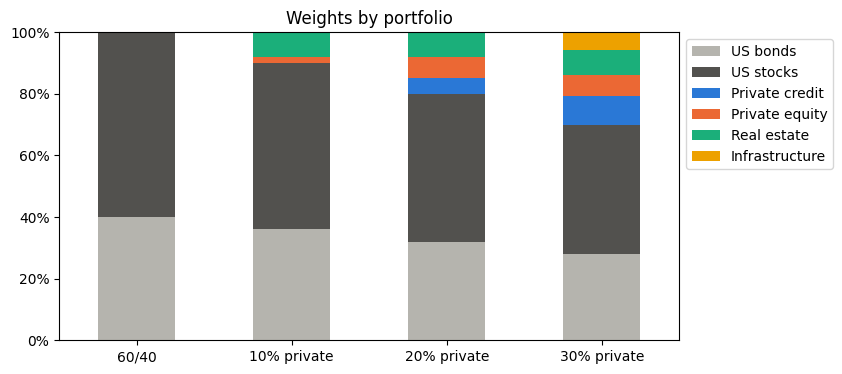

In [7]:
colors = ["#DCDBD6", "#B5B4AE", "#52514E", "#2A78D6", "#EB6834", "#1BAF7A", "#EDA100"]
table.drop("Cash").T.plot.bar(stacked=True, color=colors[1:], figsize=(8, 4), rot=0)
plt.gca().yaxis.set_major_formatter("{x:.0%}")
plt.title("Weights by portfolio"); plt.legend(bbox_to_anchor=(1, 1)); plt.show()

## 6. The lockup: what changes when private money cannot be sold for 3 years
Two rules:
- **15% cash buffer:** each private strategy keeps 15% of its money in cash, so it can pay out redemptions.
- **3-year lockup:** we simulate 10,000 possible futures, 12 quarters each. Every quarter stocks and bonds
  get rebalanced back to 60/40. The private strategies cannot be sold, so their weight drifts.

If a strategy goes over its limit in more than 5% of the futures, its target is too high.

In [8]:
# 15% cash buffer: each private strategy = 85% the asset + 15% cash
M = np.eye(7)
for i in idx:
    M[i, i], M[0, i] = 0.85, 0.15
mu_b, cov_b = M.T @ mu, M.T @ cov @ M

# 10,000 futures x 12 quarters of random returns (same seed every run)
rng = np.random.default_rng(42)
cov_q = cov / 4
drift = np.log(1 + mu) / 4 - np.diag(cov_q) / 2
R = np.exp(rng.multivariate_normal(drift, cov_q, size=(10_000, 12))) - 1

In [9]:
def simulate(w):
    """Roll a portfolio forward 12 quarters. Returns weights over time: (futures, quarters+1, assets)."""
    value = np.tile(w, (10_000, 1))
    public = [1, 2]                                  # bonds, stocks
    public_mix = w[public] / w[public].sum()
    history = [value / value.sum(1, keepdims=True)]
    for q in range(12):
        r = R[:, q, :].copy()
        r[:, idx] = 0.85 * r[:, idx] + 0.15 * r[:, [0]]    # private strategies hold 15% cash
        value = value * (1 + r)
        value[:, public] = value[:, public].sum(1, keepdims=True) * public_mix   # rebalance stocks/bonds only
        history.append(value / value.sum(1, keepdims=True))
    return np.stack(history, axis=1)

def check(w, limits):
    """For each private strategy: worst-case weight (95th percentile) and chance of going over its limit."""
    h = simulate(w)
    out = {}
    for s in private:
        peak = h[:, :, names.index(s)].max(axis=1)
        out[s] = {"target": w[names.index(s)], "p95_peak": np.quantile(peak, 0.95),
                  "over_limit": (peak > limits[s] + 1e-12).mean()}
    return pd.DataFrame(out).T

check(mixes[0.20], limits).style.format("{:.1%}")

,target,p95_peak,over_limit
Private credit,5.0%,6.9%,0.0%
Private equity,7.0%,10.4%,89.2%
Real estate,8.0%,11.4%,85.6%
Infrastructure,0.0%,0.0%,0.0%


Set a strategy right at its limit and it goes over in most futures: private assets earn more than
the 60/40 and cannot be trimmed. So each target must sit **below** its limit, with room to drift.

In [10]:
def lockup_safe_mix(X):
    """Shrink each limit by the drift we see, re-optimize, re-check, until every strategy passes."""
    guess = (1 - X) * base
    guess[idx] = X / 4
    room = {s: r["p95_peak"] / r["target"] for s, r in check(guess, limits).iterrows()}
    for _ in range(8):
        safe = {s: limits[s] / room[s] for s in private}
        if sum(safe.values()) < X:
            return None, sum(safe.values())              # does not fit
        w = best_mix(X, safe, mu_b, cov_b)
        result = check(w, limits)
        if (result["over_limit"] <= 0.05 + 1e-9).all():
            return w, sum(safe.values())
        for s, r in result.iterrows():
            if r["target"] > 1e-6:
                room[s] = max(room[s], r["p95_peak"] / r["target"] * 1.002)
    return None, sum(safe.values())

for X in levels:
    w, max_fit = lockup_safe_mix(X)
    if w is None:
        print(f"{X:.0%}: does NOT fit. The limits allow at most {max_fit:.1%} under the lockup.")
    else:
        print(f"{X:.0%}: fits.  Sharpe {sharpe(w, mu_b, cov_b):.3f}  (was {sharpe(mixes[X]):.3f} without the lockup)")

10%: fits.  Sharpe 0.377  (was 0.384 without the lockup)
20%: fits.  Sharpe 0.400  (was 0.414 without the lockup)
30%: does NOT fit. The limits allow at most 25.6% under the lockup.


## 7. Efficient frontier
For each target return, the lowest-risk portfolio. Three versions: stocks and bonds only, with private
strategies, and with the cash buffer + lockup (every point simulated).

In [11]:
def min_risk_portfolio(target, m, c, caps, priv):
    """Lowest-volatility weights that hit a target return (max 30% private in total)."""
    rules = [{"type": "eq", "fun": lambda w: w.sum() - 1},
             {"type": "eq", "fun": lambda w: w @ m - target}]
    if priv:
        rules.append({"type": "ineq", "fun": lambda w: 0.30 - w[priv].sum()})
    best = None
    for start in [np.full(len(m), 1 / len(m)), np.array(caps) / sum(caps)]:
        r = minimize(lambda w: w @ c @ w, start, method="SLSQP", bounds=[(0, k) for k in caps],
                     constraints=rules, options={"ftol": 1e-14, "maxiter": 1000})
        if r.success and (best is None or r.fun < best.fun):
            best = r
    return None if best is None else best.x.clip(min=0)


def lockup_safe_point(target, m, c, caps, priv, cols):
    """Same as above, but shrink any limit that gets broken in the lockup simulation."""
    caps = list(caps)
    for _ in range(10):
        w = min_risk_portfolio(target, m, c, caps, priv)
        if w is None:
            return None
        full = np.zeros(7)
        full[cols] = np.where(w > 1e-7, w, 0)
        result = check(full, limits)
        broken = result[result["over_limit"] > 0.05 + 1e-9]
        if broken.empty:
            return w
        for s, r in broken.iterrows():
            k = cols.index(names.index(s))
            caps[k] = min(caps[k], limits[s] * r["target"] / r["p95_peak"] * 0.998)
    return None

In [12]:
def return_range(m, c, caps, priv, lockup):
    """Lowest and highest target return to draw the frontier between."""
    rules = [{"type": "eq", "fun": lambda w: w.sum() - 1}]
    if priv:
        rules.append({"type": "ineq", "fun": lambda w: 0.30 - w[priv].sum()})
    start, bounds = np.full(len(m), 1 / len(m)), [(0, k) for k in caps]
    hi_w = minimize(lambda w: -(w @ m), start, method="SLSQP", bounds=bounds, constraints=rules).x
    if lockup:
        return m.min(), hi_w @ m
    lo_w = minimize(lambda w: w @ c @ w, start, method="SLSQP", bounds=bounds, constraints=rules).x
    return lo_w @ m, hi_w @ m - 1e-6


def frontier(mu, cov, cols, limits={}, lockup=False):
    m, c = mu[cols], cov[np.ix_(cols, cols)]
    priv = [k for k, i in enumerate(cols) if i in idx]
    caps = [limits.get(names[i], 1.0) for i in cols]
    lo, hi = return_range(m, c, caps, priv, lockup)
    points = []
    for target in np.linspace(lo, hi, 30 if lockup else 40):
        if lockup:
            w = lockup_safe_point(target, m, c, caps, priv, cols)
        else:
            w = min_risk_portfolio(target, m, c, caps, priv)
        if w is not None:
            points.append((np.sqrt(w @ c @ w), w @ m))
    points.sort()
    efficient = [p for k, p in enumerate(points) if p[1] > max([q[1] for q in points[:k]], default=-1)]
    return np.array(efficient)


f_public  = frontier(mu, cov, [1, 2])                                  # stocks + bonds
f_private = frontier(mu, cov, [1, 2] + idx, limits)                     # + private strategies
f_lockup  = frontier(mu_b, cov_b, [1, 2] + idx, limits, lockup=True)    # + cash buffer and lockup

Stocks + bonds only    return at the 60/40's risk: 6.73%
With private           return at the 60/40's risk: 7.61%
With buffer + lockup   return at the 60/40's risk: 7.26%


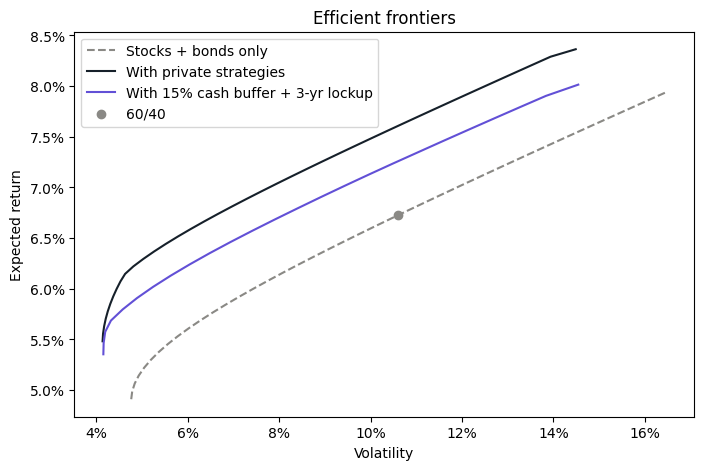

In [13]:
v0 = port_vol(base)
at_6040 = {name: np.interp(v0, f[:, 0], f[:, 1]) for name, f in
           [("Stocks + bonds only", f_public), ("With private", f_private), ("With buffer + lockup", f_lockup)]}
for name, r in at_6040.items():
    print(f"{name:22s} return at the 60/40's risk: {r:.2%}")

plt.figure(figsize=(8, 5))
plt.plot(*f_public.T, "--", color="#8A8985", label="Stocks + bonds only")
plt.plot(*f_private.T, color="#16202A", label="With private strategies")
plt.plot(*f_lockup.T, color="#6250D6", label="With 15% cash buffer + 3-yr lockup")
plt.scatter(port_vol(base), port_return(base), color="#8A8985", zorder=3, label="60/40")
plt.xlabel("Volatility"); plt.ylabel("Expected return"); plt.legend()
plt.gca().xaxis.set_major_formatter("{x:.0%}"); plt.gca().yaxis.set_major_formatter("{x:.1%}")
plt.title("Efficient frontiers"); plt.show()

## 8. Data pull: check against real price history
Private assets are only priced a few times a year, so their history looks smoother than they really are.
As a sanity check, pull listed funds that track each strategy and compare their correlations.

In [14]:
import yfinance as yf

proxies = {"US stocks": "SPY", "US bonds": "AGG", "Private credit": "BIZD",
           "Private equity": "PSP", "Real estate": "VNQ", "Infrastructure": "IGF"}
prices = yf.download(list(proxies.values()), start="2015-01-01", interval="1mo",
                     auto_adjust=True, progress=False)["Close"]
returns = prices.pct_change().dropna().rename(columns={v: k for k, v in proxies.items()})[list(proxies)]

compare = pd.DataFrame({"History (listed proxy)": returns.corr()["US stocks"],
                        "J.P. Morgan (forward)": corr["US stocks"][list(proxies)]})
compare.round(2)

,History (listed proxy),J.P. Morgan (forward)
US stocks,1.00,1.00
US bonds,0.37,0.30
Private credit,0.71,0.55
Private equity,0.86,0.75
Real estate,0.75,0.35
Infrastructure,0.72,0.47


## 9. Conclusions
- **Real estate** is the strongest diversifier; **private equity** adds the most return but also adds risk.
- At the 60/40's risk level, private strategies add about **88 bps** of expected return.
  With the 15% cash buffer and 3-year lockup, about **53 bps** is left.
- Under the lockup, targets must sit 22-34% below each limit. **10% and 20% still work; 30% does not fit**
  (the limits allow at most about 25.6%).

**Limitations:** median-manager returns (no manager selection), no capital calls or J-curve, normal
returns understate tail risk, and the limits and 5% tolerance are my own assumptions.